# Intro to Machine Learning; Linear Regression Models

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
from plotnine import *
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import root_mean_squared_error

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.
**The Gen Z recognition variable is the proportion of Gen Z participants who recognized each song**

In [2]:
songs = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")
songs.describe()

,mean_millennial_recognition,mean_gen_z_recognition
count,344.000000,344.000000
mean,0.401364,0.235506
std,0.265956,0.210541
min,0.043351,0.019483
25%,0.178364,0.095589
50%,0.344978,0.155398
75%,0.584260,0.303051
max,0.991851,0.963497


1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [3]:
X = songs[["mean_millennial_recognition"]]
y = songs["mean_gen_z_recognition"]
model_GenZ = LinearRegression()
model_GenZ.fit(X, y)
print("intercept:", round(model_GenZ.intercept_, 4))
print("coef:     ", model_GenZ.coef_.round(4))
print("R²:       ", round(model_GenZ.score(X, y), 3))

intercept: -0.0481
coef:      [0.7067]
R²:        0.797


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

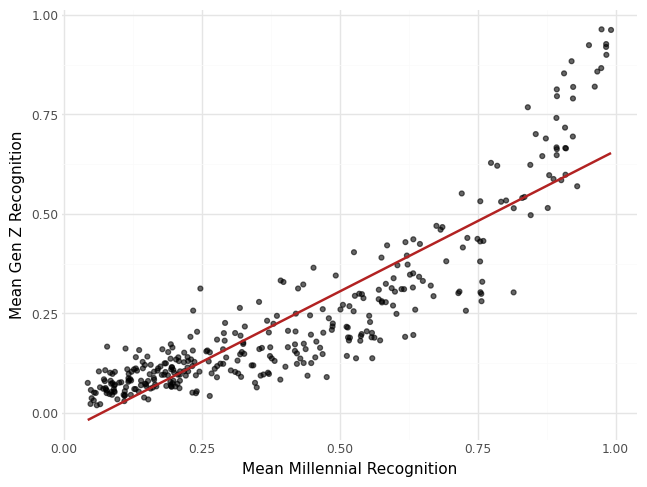

In [4]:
(ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.6)
 + geom_smooth(method="lm", se=False, color="firebrick")
 + labs(x="Mean Millennial Recognition", y="Mean Gen Z Recognition")
 + theme_minimal())

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

**Because towards the right side of the plot the y-values start increasing exponentially which can be accounted for by taking the log of the response value**

In [5]:
y_log = np.log(songs["mean_gen_z_recognition"])

log_model = LinearRegression().fit(X, y_log)
print("intercept:", round(log_model.intercept_, 4))
print("coef:     ", log_model.coef_.round(4))
print("R²:       ", round(log_model.score(X, y_log), 3))

intercept: -2.9083
coef:      [2.7992]
R²:        0.823


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

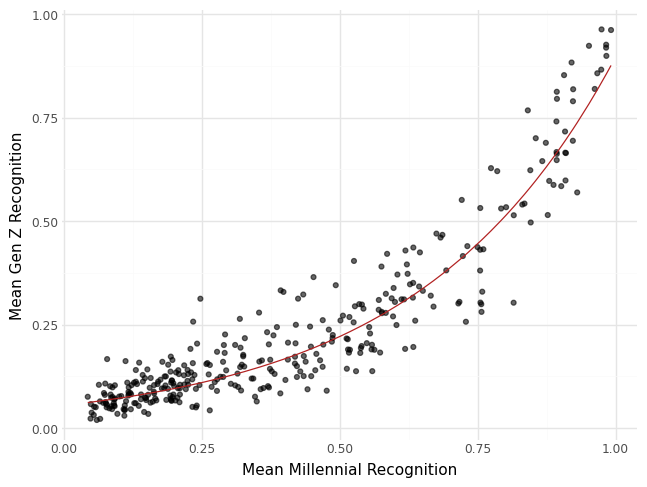

In [6]:
(
    ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
    + geom_point(alpha=0.6)
    + geom_line(aes(y=np.exp(log_model.predict(X))), color="firebrick")
    + labs(x="Mean Millennial Recognition", y="Mean Gen Z Recognition")
    + theme_minimal()
)

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(songs[["mean_millennial_recognition"]])
print(X_poly.shape)
print(poly.get_feature_names_out())

model_poly = LinearRegression().fit(X_poly, y)
print("intercept:", round(model_poly.intercept_, 4))
print("coef:     ", model_poly.coef_.round(4))
print("R²:       ", round(model_poly.score(X_poly, y), 3))

(344, 2)
['mean_millennial_recognition' 'mean_millennial_recognition^2']
intercept: 0.1085
coef:      [-0.2726  1.0207]
R²:        0.898


In [8]:
model_poly.coef_, model_poly.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257636))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

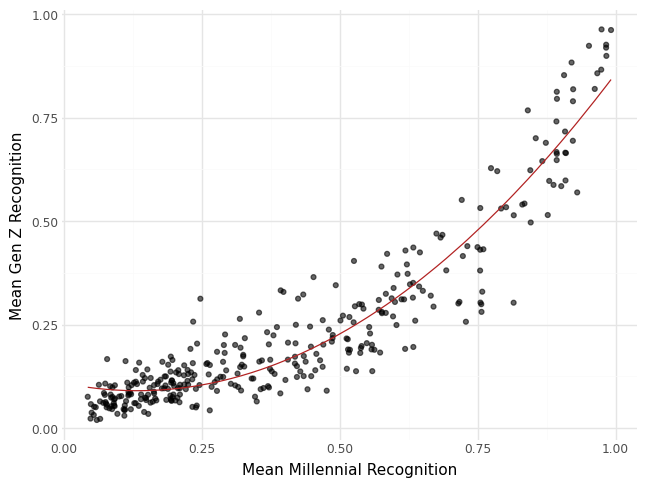

In [9]:
(
    ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
    + geom_point(alpha=0.6)
    + geom_line(aes(y=model_poly.predict(X_poly)), color="firebrick")
    + labs(x="Mean Millennial Recognition", y="Mean Gen Z Recognition")
    + theme_minimal()
)

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [10]:
# Separate train and test rows
train = songs.drop(index=325)
test = songs.loc[[325]] # Warren G, Regulate

X_train = train[["mean_millennial_recognition"]]
X_test = test[["mean_millennial_recognition"]]

y_train = train["mean_gen_z_recognition"]
y_test = test["mean_gen_z_recognition"]

In [11]:
# Fit linear model
linear_model = LinearRegression().fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_rmse = root_mean_squared_error(y_test, linear_pred)

print("Linear RMSE:", round(linear_rmse, 4))

Linear RMSE: 0.0718


In [12]:
# Fit log model
log_model = LinearRegression().fit(X_train, np.log(y_train))

log_pred = np.exp(log_model.predict(X_test))

log_rmse = root_mean_squared_error(y_test, log_pred)

print("Log RMSE:", round(log_rmse, 4))

Log RMSE: 0.0056


In [13]:
# Fit poly model
poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

poly_model = LinearRegression().fit(X_poly_train, y_train)

poly_pred = poly_model.predict(X_poly_test)

poly_rmse = root_mean_squared_error(y_test, poly_pred)

print("Polynomial RMSE:", round(poly_rmse, 4))

Polynomial RMSE: 0.0056


In [14]:
# Compare model results
results = pd.DataFrame({
    "Model": ["Linear", "Log-linear", "Polynomial"],
    "Prediction": [linear_pred[0], log_pred[0], poly_pred[0]],
    "RMSE": [linear_rmse, log_rmse, poly_rmse]
})

print("Actual Gen Z Recognition:", y_test.iloc[0])

results

Actual Gen Z Recognition: 0.1967554126090711


,Model,Prediction,RMSE
0,Linear,0.268601,0.071845
1,Log-linear,0.191155,0.005600
2,Polynomial,0.191124,0.005632


**Both the Log and Polynomial models appear to give the best prediction as they both have RMSE values of roughly 0.0056. If we get down to minute differences between them, the Log model performs ever so slightly better, predicting 0.1912 vs the Polynomial predicting 0.1911, but this is likely insignificant**

8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [15]:
new_song = pd.DataFrame({"mean_millennial_recognition": [0.7]})

# Linear model
linear_pred = linear_model.predict(new_song)

# Log model
log_pred = np.exp(log_model.predict(new_song))

# Poly model
poly_pred = poly_model.predict(poly.transform(new_song))

print("Linear:", linear_pred[0])
print("Log-linear:", log_pred[0])
print("Polynomial:", poly_pred[0])

Linear: 0.446812099090963
Log-linear: 0.38713799540957505
Polynomial: 0.4177944623843955


**Since we are not given the true value for the Gen Z recognition of "Smells Like Teen Spirit", we cannot say for sure which model gives the best prediction**

## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [16]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [17]:
df_fev["Smoking status"] = df_fev["Smoking status"].astype("category")
df_fev["smoker"] = (df_fev["Smoking status"] == "smoker").astype(int)

In [18]:
X = df_fev[["smoker"]]
y = df_fev["FEV"]
model_smoking = LinearRegression()
model_smoking.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [19]:
predictions = model_smoking.predict(pd.DataFrame({"smoker": [0, 1]}))

print("Non-smoker:", predictions[0])
print("Smoker:", predictions[1])

Non-smoker: 2.5661426146010187
Smoker: 3.276861538461539


**Non-smokers are predicted to have lower FEV values than smokers. We could have known this because we have previously discussed that there are confounding variables including age and height that positively correlate with smoking as well as increased FEV**

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

**While it may not be what someone might expect, since there are confounding variables contributing to the FEV values I did expect smokers to have higher FEV values than non-smokers, given the differences in sample popuation**

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

**Smokers tend to be older with better developed lungs, whereas non-smokers in this study tend to be younger with less-developed lungs**

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [20]:
X2 = df_fev[["smoker", "Age (months)"]]
y = df_fev["FEV"]
model_smoking_age = LinearRegression().fit(X2, y)

6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

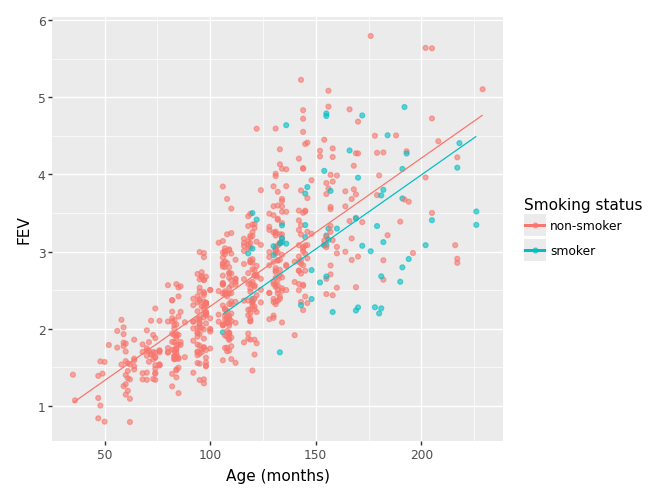

In [21]:
(
    ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
    + geom_point(alpha=0.6)
    + geom_line(aes(y=model_smoking_age.predict(X2), group="Smoking status"))
)

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [22]:
df_fev["Age_x_smoker"] = df_fev["Age (months)"] * df_fev["smoker"]
X3 = df_fev[["Age (months)", "smoker", "Age_x_smoker"]]
model_3 = LinearRegression().fit(X3, y)
print(pd.Series(model_3.coef_, index=X3.columns).round(5))

Age (months)    0.02016
smoker          1.87006
Age_x_smoker   -0.01311
dtype: float64


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

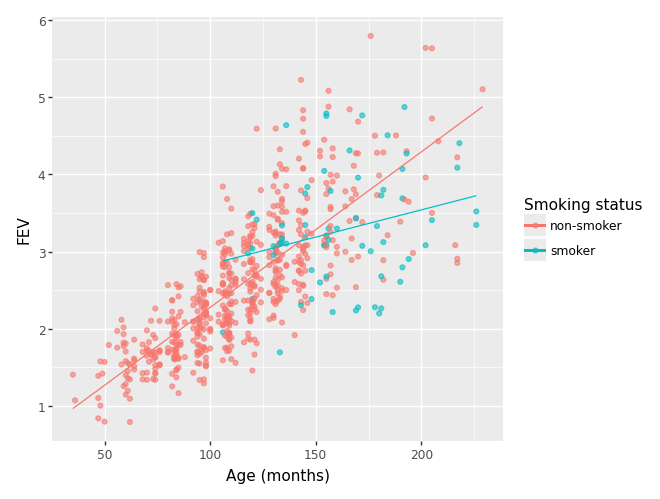

In [23]:
(
    ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
    + geom_point(alpha=0.6)
    + geom_line(aes(y=model_3.predict(X3), group="smoker"))
)

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

In [24]:
print("Smoking only:",
      root_mean_squared_error(y, model_smoking.predict(X)))

print("Smoking + Age:",
      root_mean_squared_error(y, model_smoking_age.predict(X2)))

print("Smoking + Age + Interaction:",
      root_mean_squared_error(y, model_3.predict(X3)))

Smoking only: 0.839897832885257
Smoking + Age: 0.564220390501191
Smoking + Age + Interaction: 0.5533802977049908


**Based off the RMSE of each model, model 3 is the "best" at predicting FEV values because age it allows the relationship between age and FEV to differ between smoking groups, whereas model 2 assumes a constant slope between groups.**

**To further evaluate the models, I would compare their RMSE values using a training and test split.**